**Célula 1 – setup e pesquisa do 1.º vizinho de todas as queries:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits
from src.representation import load_autoencoder, ae_encode
from src.retrieval import SearchSpace

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

ae = load_autoencoder(32, "models/ae_32.pt")
space = SearchSpace("learned (AE-32)", lambda X: ae_encode(ae, X), X_train)

idx, dist = space.search(X_test, k=1)              
nn_idx, nn_dist = idx[:, 0], dist[:, 0]
nn_label = y_train[nn_idx]                         
mismatch = nn_label != y_test                     
print(f"Queries cujo 1.º vizinho é de outra classe: {mismatch.sum()} ({mismatch.mean():.1%})")

Queries cujo 1.º vizinho é de outra classe: 1475 (14.8%)


**Célula 2 – que pares de classes se confundem mais:**

In [2]:
pairs = pd.DataFrame({"query class": [CLASS_NAMES[c] for c in y_test[mismatch]],
                      "top-1 neighbour class": [CLASS_NAMES[c] for c in nn_label[mismatch]]})
pair_counts = pairs.value_counts().reset_index(name="count").head(10)
print(pair_counts.to_string(index=False))
pair_counts.to_csv("results/tables/15_top_confused_pairs.csv", index=False)

query class top-1 neighbour class  count
T-shirt/top                 Shirt    158
      Shirt           T-shirt/top    145
       Coat              Pullover    135
   Pullover                  Coat    111
      Shirt              Pullover    104
   Pullover                 Shirt    104
       Coat                 Shirt     88
      Shirt                  Coat     87
     Sandal               Sneaker     43
    Sneaker            Ankle boot     43


**Célula 3 – tipo 1: parecidas mas com labels diferentes (6 casos):**

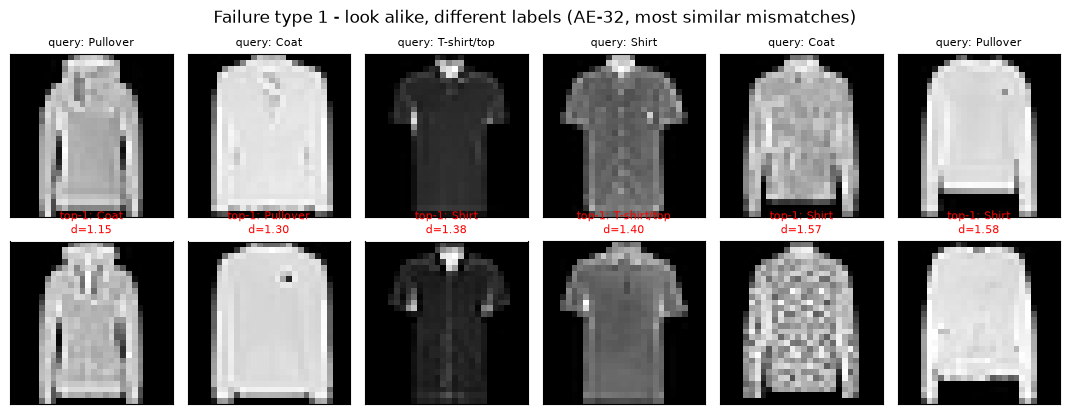

Índices de teste usados: [np.int64(4110), np.int64(994), np.int64(8007), np.int64(6499), np.int64(4839), np.int64(1981)]


In [3]:
order = np.argsort(nn_dist)                        
seen, cases = set(), []
for q in order:
    if not mismatch[q]:
        continue
    key = (y_test[q], nn_label[q])                 
    if key in seen:                               
        continue
    seen.add(key)
    cases.append(q)
    if len(cases) == 6:
        break

fig, axes = plt.subplots(2, len(cases), figsize=(len(cases) * 1.8, 4.2))
for j, q in enumerate(cases):
    axes[0, j].imshow(X_test[q].reshape(28, 28), cmap="gray")
    axes[0, j].set_title(f"query: {CLASS_NAMES[y_test[q]]}", fontsize=8)
    axes[1, j].imshow(X_train[nn_idx[q]].reshape(28, 28), cmap="gray")
    axes[1, j].set_title(f"top-1: {CLASS_NAMES[nn_label[q]]}\nd={nn_dist[q]:.2f}", fontsize=8, color="red")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Failure type 1 - look alike, different labels (AE-32, most similar mismatches)")
plt.tight_layout()
plt.savefig("results/figures/15_failure_lookalike_different_label.png", dpi=150, bbox_inches="tight")
plt.show()
print("Índices de teste usados:", cases)

**Célula 4 – tipo 2: mesma label, estilos diferentes (k-means com 2 grupos):**

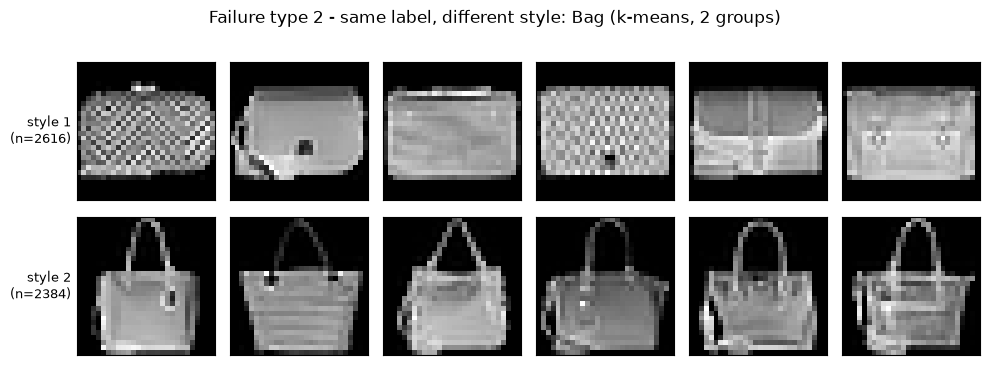

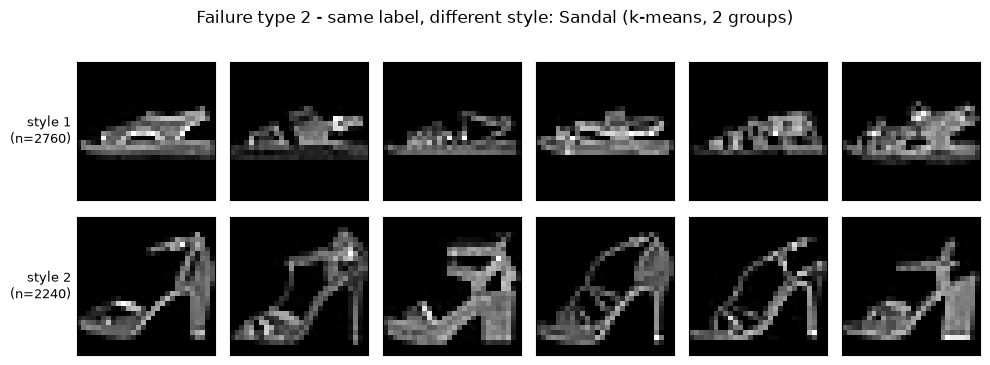

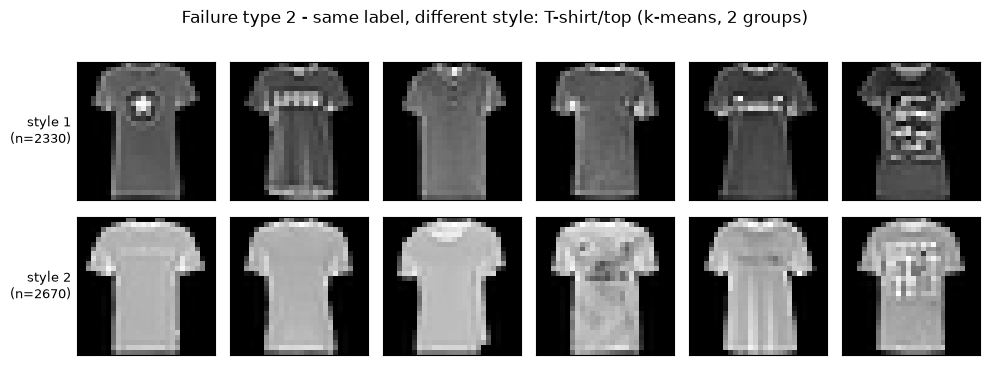

In [4]:
Z_gal = space.gallery_features                    

for c in [8, 5, 0]:                                
    idx_c = np.where(y_train == c)[0]            
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(Z_gal[idx_c]) 

    fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
    for g in range(2):
        members = idx_c[km.labels_ == g]
        d = np.linalg.norm(Z_gal[members] - km.cluster_centers_[g], axis=1) 
        show = members[np.argsort(d)[:6]]                                    
        for j, i in enumerate(show):
            axes[g, j].imshow(X_train[i].reshape(28, 28), cmap="gray")
            axes[g, j].set_xticks([]); axes[g, j].set_yticks([])
        axes[g, 0].set_ylabel(f"style {g + 1}\n(n={len(members)})", fontsize=9, rotation=0,
                              ha="right", va="center")
    name = CLASS_NAMES[c].replace("/", "-")
    plt.suptitle(f"Failure type 2 - same label, different style: {CLASS_NAMES[c]} (k-means, 2 groups)")
    plt.tight_layout()
    plt.savefig(f"results/figures/15_failure_same_label_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()